# Hotel Booking Cancellation Prediction


**Structure:**
Load data
1. Pre-processing
2. EDA
3. Feature engineering
4. Classifier training
5. Feature importance

## Load Data

Read the `hotel_bookings.csv` file (inside the Hotel_Booking folder) that was shared on Brightspace.

In [1]:
# Libraries used throughout the notebook
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
RANDOM_STATE = 42    # fixed seed so every run gives the same split and the same trees

In [2]:
# Read the dataset (in Colab, upload the file when asked if it cannot be found)
candidate_paths = ['Hotel_Booking/hotel_bookings.csv', 'hotel_bookings.csv', '/content/hotel_bookings.csv']
csv_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if csv_path is None:
    from google.colab import files
    uploaded = files.upload()
    csv_path = list(uploaded.keys())[0]

df = pd.read_csv(csv_path)
print('Dataset size (rows, columns):', df.shape)
df.head()

Dataset size (rows, columns): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Column names, data types and non-null counts, plus the balance of the target
df.info()
print()
print('Share of is_canceled values:')
print(df['is_canceled'].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

# 1. Data Pre-processing (25%)

## Drop irrelevant columns

Identifiers, dates and any field that is only filled in once the outcome of a booking is known are of little use for prediction, and the latter even cause **data leakage**. To base the choices on facts, I first count duplicate rows and missing values.

In [4]:
# Duplicated rows describe the same booking more than once, so they are removed
print('Duplicate rows found:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

# Share of missing values per column (only columns that actually have missing values)
missing_share = df.isna().mean() * 100
print()
print('Missing values (%):')
print(missing_share[missing_share > 0].round(2))

Duplicate rows found: 31994
Shape after removing duplicates: (87396, 32)

Missing values (%):
children     0.00
country      0.52
agent       13.95
company     93.98
dtype: float64


In [5]:
redundant_cols = [
    'agent',                      # travel agency ID, roughly 14% missing
    'company',                    # company ID, roughly 94% missing
    'arrival_date_year',          # date column, only 3 years so no use for future bookings
    'arrival_date_week_number',   # date column (the month is kept instead)
    'arrival_date_day_of_month',  # date column
    'reservation_status_date',    # date column, only known AFTER the outcome of the booking
    'reservation_status',         # Canceled / Check-Out / No-Show -> the target in disguise (leakage!)
    'assigned_room_type',         # decided at check-in, so unknown when a cancellation is predicted
]
df = df.drop(columns=redundant_cols)
print('Shape after dropping columns:', df.shape)
print(list(df.columns))

Shape after dropping columns: (87396, 24)
['hotel', 'is_canceled', 'lead_time', 'arrival_date_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


**Why these columns were dropped**
- `agent` and `company` are ID numbers, and `company` is almost entirely empty, so neither helps the model.
- The year, week number, day of month and `reservation_status_date` are date fields. I keep just `arrival_date_month`, because it still expresses the seasonal pattern.
- `reservation_status` reveals the outcome of the booking directly (leakage: the model would simply read the answer). `assigned_room_type` is set at check-in, so at the time of a real prediction it would not yet exist.

## Unique values

Look at the unique values per column to find entries that do not look consistent.

In [6]:
# Text columns: how many distinct values each has, plus the most frequent ones
for col in df.select_dtypes(exclude='number').columns:
    print(f'Column: {col} | distinct values: {df[col].nunique()}')
    print(df[col].value_counts().head(10).to_string())
    print()

Column: hotel | distinct values: 2
hotel
City Hotel      53428
Resort Hotel    33968

Column: arrival_date_month | distinct values: 12
arrival_date_month
August       11257
July         10057
May           8355
April         7908
June          7765
March         7513
October       6934
September     6690
February      6098
December      5131

Column: meal | distinct values: 5
meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360

Column: country | distinct values: 177
country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
IRL     3016
BEL     2081
BRA     1995
NLD     1911

Column: market_segment | distinct values: 8
market_segment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2

Column: distribution_channel | distinct values: 5
distribution_channel
TA/TO        69141
Direct  

In [7]:
# Numeric columns: min, max, mean ... helps to spot impossible values
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,87396.0,0.274898,0.446466,0.00,0.0,0.0,1.0,1.0
lead_time,87396.0,79.891368,86.052325,0.00,11.0,49.0,125.0,737.0
stays_in_weekend_nights,87396.0,1.005263,1.031921,0.00,0.0,1.0,2.0,19.0
stays_in_week_nights,87396.0,2.625395,2.053584,0.00,1.0,2.0,4.0,50.0
adults,87396.0,1.875795,0.626500,0.00,2.0,2.0,2.0,55.0
children,87392.0,0.138640,0.455881,0.00,0.0,0.0,0.0,10.0
babies,87396.0,0.010824,0.113597,0.00,0.0,0.0,0.0,10.0
is_repeated_guest,87396.0,0.039075,0.193775,0.00,0.0,0.0,0.0,1.0
previous_cancellations,87396.0,0.030413,0.369145,0.00,0.0,0.0,0.0,26.0
previous_bookings_not_canceled,87396.0,0.183990,1.731894,0.00,0.0,0.0,0.0,72.0


**Observations from the unique values / summary above**
- `meal`, `market_segment` and `distribution_channel` have an `'Undefined'` entry. In `meal` it is equivalent to `'SC'` (no meal package).
- `adults` includes 0 adults and implausibly high values such as 20 and 55.
- `children` is a decimal column with a few gaps, and `babies` has odd values like 9 and 10.
- `adr` (average daily rate) contains a negative number and an extreme maximum of 5400.
- A number of bookings have no nights at all (weekend and week nights are both 0).

## 1.1 Missing Values (10%)

Find the missing values and decide how to deal with them.

In [8]:
# Columns that still have missing values after the drop above
na_counts = df.isnull().sum()
print(na_counts[na_counts > 0])

children      4
country     452
dtype: int64


In [9]:
# children: very few missing values and most bookings have no children -> fill with 0
# children -> 0 (the typical value); country -> 'Unknown' (the row is kept, with its own label)
df = df.fillna({'children': 0, 'country': 'Unknown'})

print('Missing values remaining:', df.isnull().sum().sum())

Missing values remaining: 0


**Reasoning:** With `agent` and `company` removed, gaps only remain in `children` and `country`. Dropping those rows would lose useful records, so I fill the gaps instead: `children` gets 0 (by far the most common value, and very few rows are involved), and `country` gets `'Unknown'`, a label of its own that does not invent any information.

## 1.2 Removing Inconsistent values and Outliers (10%)

Look for bookings without guests and for bookings that last zero nights.

In [10]:
rows_in = len(df)

# 1) meal: 'Undefined' and 'SC' both mean "no meal package" -> merge them
df['meal'] = df['meal'].replace('Undefined', 'SC')

# 2) 'Undefined' market segment / distribution channel -> only a few rows, so drop them
bad_label = (df['market_segment'] == 'Undefined') | (df['distribution_channel'] == 'Undefined')
print('Rows with an Undefined market segment / channel:', bad_label.sum())
df = df[~bad_label]

# 3) incomplete bookings: no adults (this also covers 0 adults + 0 children + 0 babies)
print('Bookings with 0 adults:', (df['adults'] == 0).sum())
df = df[df['adults'] > 0]

# 4) bookings with 0 nights (0 weekend nights and 0 week nights)
no_nights = (df['stays_in_weekend_nights'] + df['stays_in_week_nights']) == 0
print('Bookings with 0 nights:', no_nights.sum())
df = df[~no_nights]

print('Rows before:', rows_in, '| rows after:', len(df), '| removed:', rows_in - len(df))

Rows with an Undefined market segment / channel: 5
Bookings with 0 adults: 385
Bookings with 0 nights: 591
Rows before: 87396 | rows after: 86415 | removed: 981


**Reasoning:** A booking with no adults (children and babies cannot reserve alone), a stay of zero nights or a negative price cannot be a real, complete booking, so I remove them. `'Undefined'` meals are merged into `'SC'` since they mean the same. Only a small part of the data is lost this way.

### Outliers (box plots)

In [12]:
# Numeric columns that will be checked for outliers (box plots BEFORE removing outliers)
num_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults',
            'children', 'babies', 'adr', 'days_in_waiting_list']

In [13]:
# Are there text values hiding inside the numeric columns?
for col in num_cols:
    converted = pd.to_numeric(df[col], errors='coerce')
    bad = converted.isna() & df[col].notna()
    if bad.sum() > 0:
        print(f"Column '{col}' has {bad.sum()} non-numeric values, e.g. {df.loc[bad, col].unique()[:5]}")
print('Check finished.')

Check finished.


In [14]:
# Convert the numeric columns to numbers; anything that cannot be converted becomes NaN and is dropped
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

before = len(df)
df = df.dropna(subset=num_cols)
print('Rows dropped because of non-numeric values:', before - len(df))

Rows dropped because of non-numeric values: 0


In [15]:
# Final check: every column in num_cols must now be numeric
for col in num_cols:
    has_text = df[col].map(lambda v: isinstance(v, str)).any()
    print(f'{col:25s} numeric: {pd.api.types.is_numeric_dtype(df[col])} | contains text: {has_text}')

lead_time                 numeric: True | contains text: False
stays_in_weekend_nights   numeric: True | contains text: False
stays_in_week_nights      numeric: True | contains text: False
adults                    numeric: True | contains text: False
children                  numeric: True | contains text: False
babies                    numeric: True | contains text: False
adr                       numeric: True | contains text: False
days_in_waiting_list      numeric: True | contains text: False


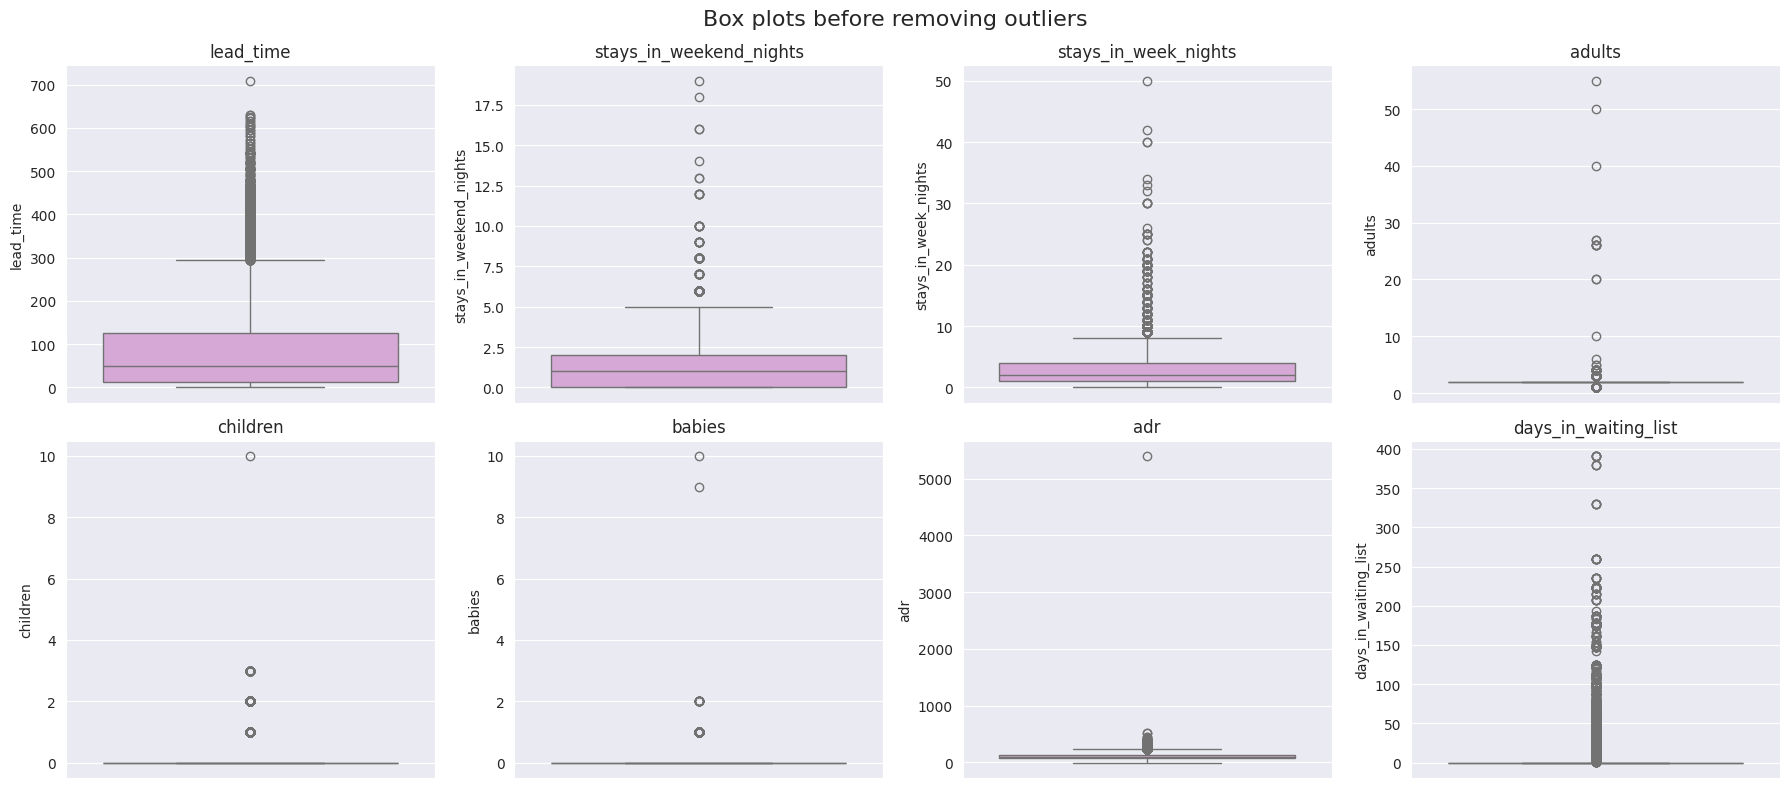

lead_time                 max =    709.0 | upper whisker =   294.5 | points above = 2448
stays_in_weekend_nights   max =     19.0 | upper whisker =     5.0 | points above = 213
stays_in_week_nights      max =     50.0 | upper whisker =     8.5 | points above = 1511
adults                    max =     55.0 | upper whisker =     2.0 | points above = 5994
children                  max =     10.0 | upper whisker =     0.0 | points above = 8111
babies                    max =     10.0 | upper whisker =     0.0 | points above = 906
adr                       max =   5400.0 | upper whisker =   227.5 | points above = 2479
days_in_waiting_list      max =    391.0 | upper whisker =     0.0 | points above = 854


In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax, color='plum')
    ax.set_title(col)
plt.suptitle('Box plots before removing outliers', fontsize=16)
plt.tight_layout()
plt.show()

# How far is the maximum from the upper whisker (Q3 + 1.5 * IQR), and how many points lie above it?
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    whisker = q3 + 1.5 * (q3 - q1)
    print(f'{col:25s} max = {df[col].max():8.1f} | upper whisker = {whisker:7.1f} | points above = {(df[col] > whisker).sum()}')

**What the box plots show**
- `adults`, `children`, `babies`, both stay-length columns and `adr` each have a handful of extreme, unrealistic points (e.g. 55 adults, 10 babies, a 50-night stay, an `adr` of 5400) that squeeze the rest of the plot. They look like typing errors, so I cut them off with reasonable limits.
- `lead_time` and `days_in_waiting_list` also show many points beyond the whisker, but that is **genuine behaviour** (people reserving over a year ahead). I keep them and tame the skew with **binning** later, instead of deleting thousands of valid bookings.

In [17]:
# OUTLIER HANDLING
n_before = len(df)

# 1. Invalid records: none of these features can be negative
non_negative = ['adults', 'children', 'babies', 'adr', 'lead_time',
                'stays_in_weekend_nights', 'stays_in_week_nights']
df = df[(df[non_negative] >= 0).all(axis=1)]

# 2. Extremely high prices are treated as errors
df = df[df['adr'].between(0, 1000)]

# 3. Unrealistic numbers of guests
df = df[(df['adults'] <= 10) & (df['children'] <= 10) & (df['babies'] <= 5)]

# 4. Unrealistically long stays (long but realistic stays are kept)
df = df[(df['stays_in_weekend_nights'] <= 14) & (df['stays_in_week_nights'] <= 25)]

print('Rows removed:', n_before - len(df))
print('Rows remaining:', len(df))

Rows removed: 28
Rows remaining: 86387


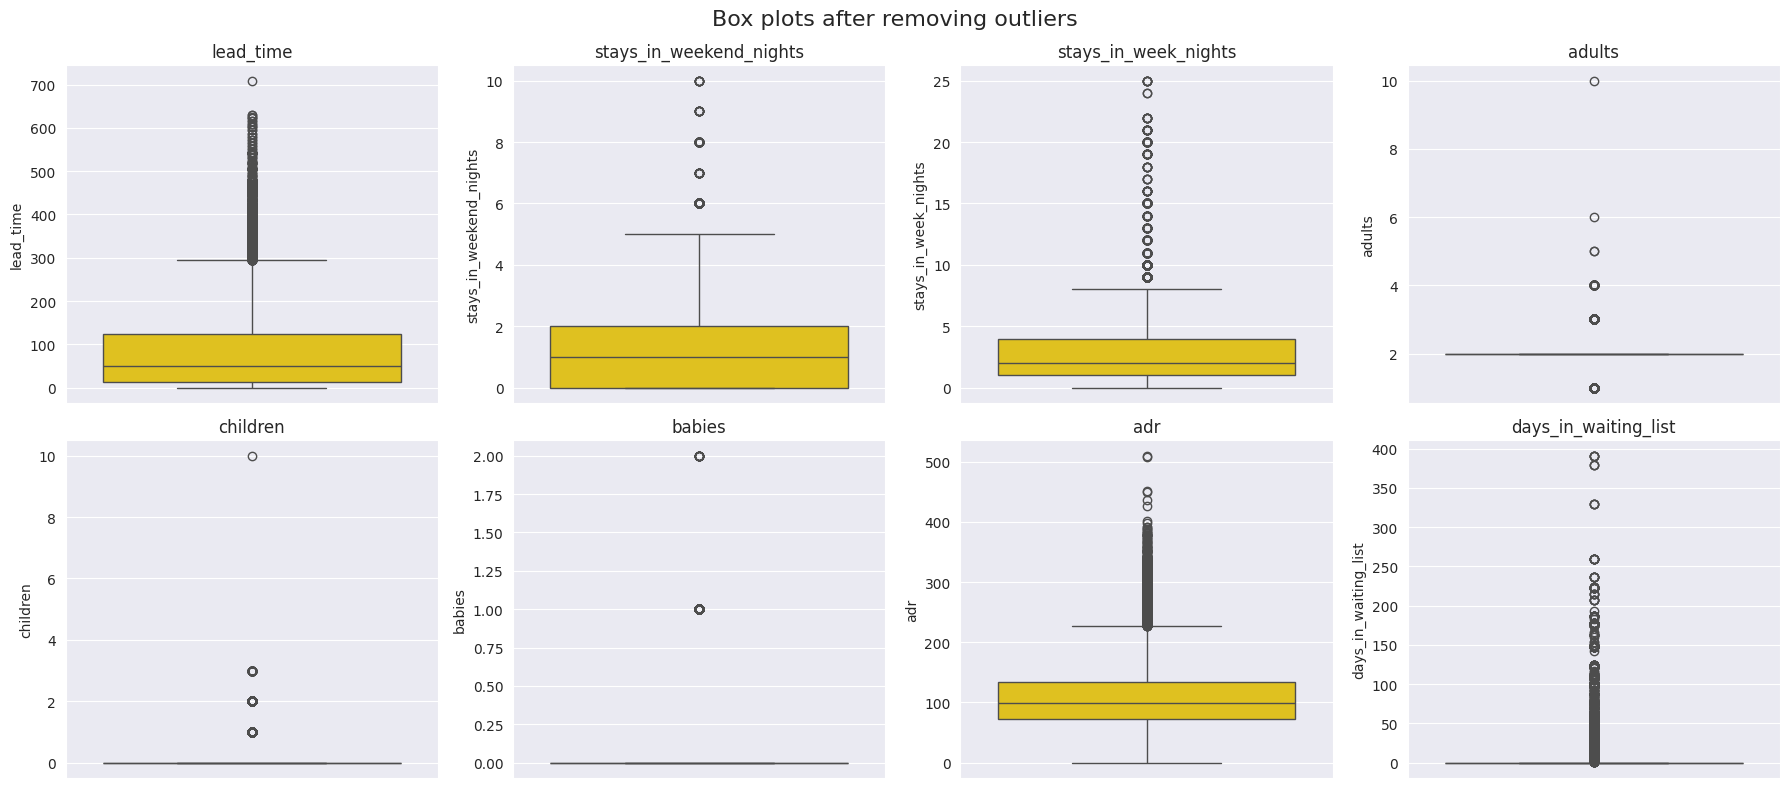

In [18]:
# Box plots AFTER removing outliers
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax, color='gold')
    ax.set_title(col)
plt.suptitle('Box plots after removing outliers', fontsize=16)
plt.tight_layout()
plt.show()

## 1.3 Column data type conversion (5%)

Convert every column that needs it to a suitable data type.

In [19]:
print(df.dtypes)

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_month                 object
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
booking_changes                     int64
deposit_type                       object
days_in_waiting_list                int64
customer_type                      object
adr                               float64
required_car_parking_spaces         int64
total_of_special_requests         

In [20]:
# children was read as a decimal (because of the missing values) -> whole number
df['children'] = df['children'].astype(int)

# text columns with a limited set of values -> 'category'
cat_cols = ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel',
            'reserved_room_type', 'deposit_type', 'customer_type']
df[cat_cols] = df[cat_cols].astype('category')

# the month is an ordered category (January ... December)
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
               'August', 'September', 'October', 'November', 'December']
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

# is_canceled and is_repeated_guest are 0/1 flags -> they stay integers so the model can use them directly
print(df.dtypes)

hotel                             category
is_canceled                          int64
lead_time                            int64
arrival_date_month                category
stays_in_weekend_nights              int64
stays_in_week_nights                 int64
adults                               int64
children                             int64
babies                               int64
meal                              category
country                           category
market_segment                    category
distribution_channel              category
is_repeated_guest                    int64
previous_cancellations               int64
previous_bookings_not_canceled       int64
reserved_room_type                category
booking_changes                      int64
deposit_type                      category
days_in_waiting_list                 int64
customer_type                     category
adr                                float64
required_car_parking_spaces          int64
total_of_sp

**Reasoning:** `children` must be a whole number. Text columns with a fixed set of values become `category` (smaller in memory and clearer for the encoding step later), and the month is an *ordered* category so charts run from January to December. The 0/1 flags stay as integers.

# 2. Exploratory Data Analysis (25%)

Each chart is followed by an insight that is computed from the data itself.

## 2.1. Calculating cancellation percentages for City and Resort hotels.

hotel
City Hotel      30.17
Resort Hotel    23.68
Name: is_canceled, dtype: float64


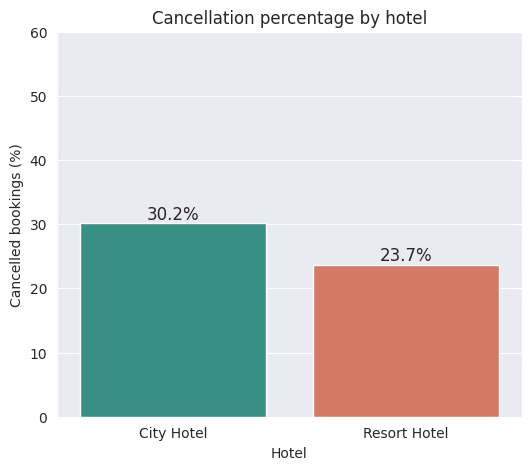

INSIGHT: Overall 27.6% of the bookings are cancelled. The City Hotel has the higher cancellation rate (30.2% vs 23.7%), so it faces more revenue risk and could benefit from stricter deposit or overbooking policies.


In [21]:
cancel_rate = df.groupby('hotel', observed=True)['is_canceled'].mean() * 100
print(cancel_rate.round(2))

plt.figure(figsize=(6, 5))
ax = sns.barplot(x=cancel_rate.index, y=cancel_rate.values, hue=cancel_rate.index,
                 palette=['#2a9d8f', '#e76f51'], legend=False)
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():.1f}%', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=12)
plt.title('Cancellation percentage by hotel')
plt.xlabel('Hotel')
plt.ylabel('Cancelled bookings (%)')
plt.ylim(0, 60)
plt.show()

overall_rate = df['is_canceled'].mean() * 100
print(f'INSIGHT: Overall {overall_rate:.1f}% of the bookings are cancelled. '
      f'The {cancel_rate.idxmax()} has the higher cancellation rate ({cancel_rate.max():.1f}% vs {cancel_rate.min():.1f}%), '
      f'so it faces more revenue risk and could benefit from stricter deposit or overbooking policies.')

## 2.2. Identifying the most frequently ordered meal types.

meal
BB (Bed & Breakfast)    67182
SC (No meal package)     9826
HB (Half board)          9020
FB (Full board)           359
Name: count, dtype: int64


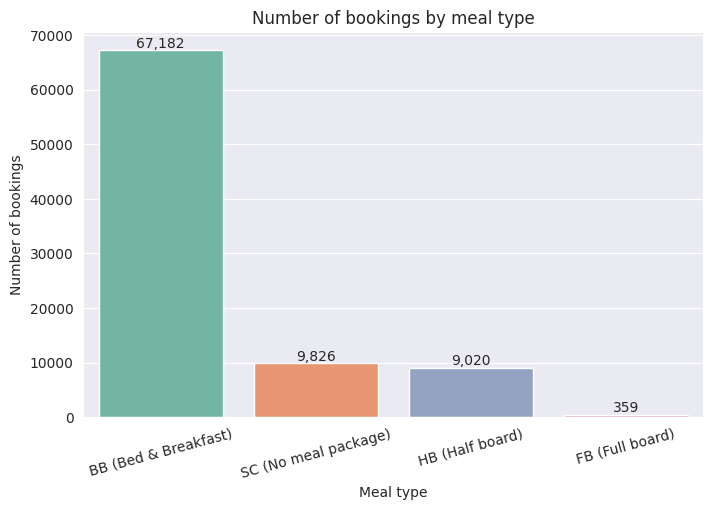

INSIGHT: BB (Bed & Breakfast) is the most frequently ordered meal type (77.8% of all bookings). Kitchen planning and meal promotions should concentrate on this package.


In [22]:
meal_labels = {'BB': 'BB (Bed & Breakfast)', 'HB': 'HB (Half board)',
               'FB': 'FB (Full board)', 'SC': 'SC (No meal package)'}
meal_counts = df['meal'].astype(str).map(meal_labels).value_counts()
print(meal_counts)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=meal_counts.index, y=meal_counts.values, hue=meal_counts.index,
                 palette='Set2', legend=False)
for bar in ax.patches:
    ax.annotate(f'{int(bar.get_height()):,}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
plt.title('Number of bookings by meal type')
plt.xlabel('Meal type')
plt.ylabel('Number of bookings')
plt.xticks(rotation=15)
plt.show()

best_meal = meal_counts.index[0]
best_share = meal_counts.iloc[0] / meal_counts.sum() * 100
print(f'INSIGHT: {best_meal} is the most frequently ordered meal type ({best_share:.1f}% of all bookings). '
      f'Kitchen planning and meal promotions should concentrate on this package.')

## 2.3. Determining the number of returning guests.

is_repeated_guest
New guest          83245
Returning guest     3142
Name: count, dtype: int64


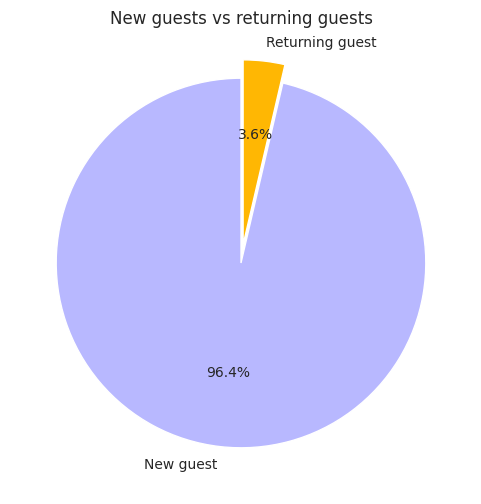

INSIGHT: Just 3,142 bookings (3.6%) come from returning guests, which leaves a lot of room for loyalty programmes. Returning guests also cancel far less (8.2% vs 28.4% for new guests), making them a more dependable customer group.


In [23]:
guest_type = df['is_repeated_guest'].map({0: 'New guest', 1: 'Returning guest'}).value_counts()
print(guest_type)

plt.figure(figsize=(6, 6))
plt.pie(guest_type.values, labels=guest_type.index, autopct='%1.1f%%',
        colors=['#b8b8ff', '#ffb703'], startangle=90, explode=[0, 0.1])
plt.title('New guests vs returning guests')
plt.show()

# cancellation rate of both groups
group_rate = df.groupby('is_repeated_guest')['is_canceled'].mean() * 100
n_return = guest_type.get('Returning guest', 0)
print(f'INSIGHT: Just {n_return:,} bookings ({n_return / len(df) * 100:.1f}%) come from returning guests, '
      f'which leaves a lot of room for loyalty programmes. Returning guests also cancel far less '
      f'({group_rate[1]:.1f}% vs {group_rate[0]:.1f}% for new guests), making them a more dependable customer group.')

## 2.4. Discovering the most booked room types.

reserved_room_type
A    55981
D    17286
E     5997
F     2803
G     2034
C      906
B      782
H      592
L        6
Name: count, dtype: int64


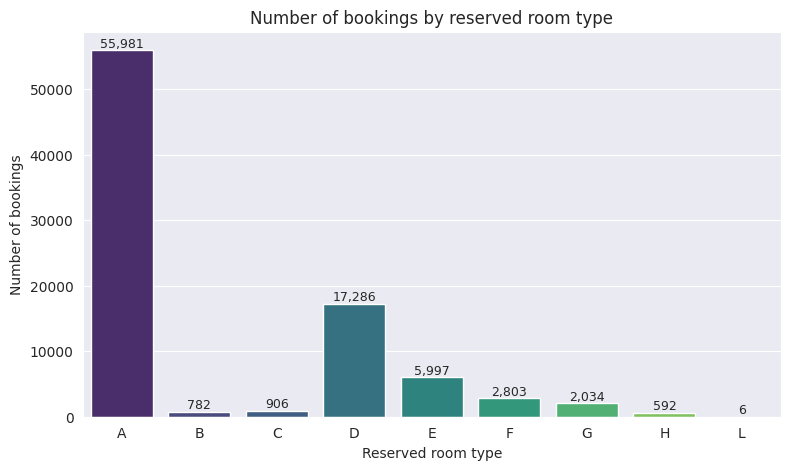

INSIGHT: Room types A and D are booked most often and together account for 84.8% of all bookings. The remaining room types are booked far less.


In [24]:
room_counts = df['reserved_room_type'].value_counts()
print(room_counts)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=room_counts.index, y=room_counts.values, hue=room_counts.index,
                 palette='viridis', legend=False)
for bar in ax.patches:
    ax.annotate(f'{int(bar.get_height()):,}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Number of bookings by reserved room type')
plt.xlabel('Reserved room type')
plt.ylabel('Number of bookings')
plt.show()

first_two = room_counts.index[:2]
first_two_share = room_counts.iloc[:2].sum() / room_counts.sum() * 100
print(f'INSIGHT: Room types {first_two[0]} and {first_two[1]} are booked most often and together account for '
      f'{first_two_share:.1f}% of all bookings. The remaining room types are booked far less.')

## 2.5. Exploring correlations between room types and cancellations.

Room type is **categorical**, so a normal Pearson `corr()` does not apply. I use two tools instead:
1. **a heatmap of cancellation rates** per room type (also split by hotel), and
2. **Cramer's V** (based on the chi-square test), which expresses how strongly two categorical variables are related (0 = unrelated, 1 = perfectly related).

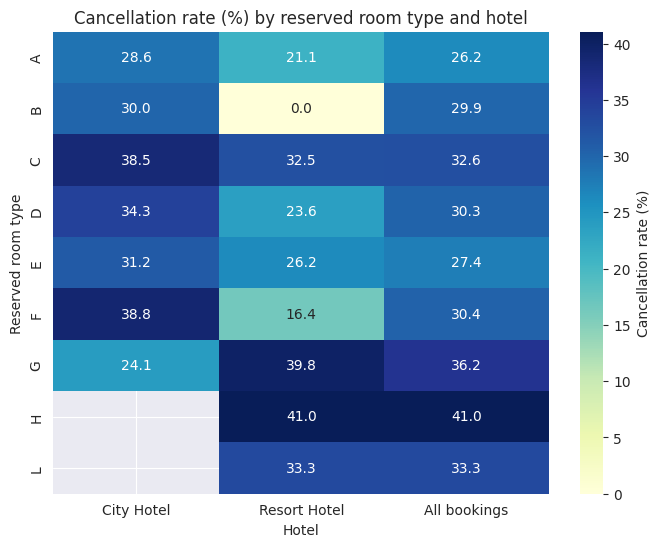

Chi-square p-value: 7.141e-54
Cramer's V: 0.056

Bookings per room type:
reserved_room_type
A    55981
D    17286
E     5997
F     2803
G     2034
C      906
B      782
H      592
L        6
INSIGHT: Cancellation rates differ between room types, from 26.2% (type A) to 41.0% (type H). Cramer's V = 0.06 with a very small p-value, so the link is statistically real but weak, i.e. room type on its own does not predict cancellation well. Rates for room types with very few bookings (see the counts above) should be read with care.


In [25]:
# Heatmap: % of bookings cancelled per room type, for each hotel and for all bookings together
rate_map = df.pivot_table(values='is_canceled', index='reserved_room_type',
                          columns='hotel', aggfunc='mean', observed=True) * 100
rate_map['All bookings'] = df.groupby('reserved_room_type', observed=True)['is_canceled'].mean() * 100

plt.figure(figsize=(8, 6))
sns.heatmap(rate_map, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Cancellation rate (%)'})
plt.title('Cancellation rate (%) by reserved room type and hotel')
plt.xlabel('Hotel')
plt.ylabel('Reserved room type')
plt.show()

# Cramer's V between room type and cancellation
contingency = pd.crosstab(df['reserved_room_type'], df['is_canceled'])
chi2, p_value, dof, expected = chi2_contingency(contingency)
n_obs = contingency.values.sum()
cramers_v = np.sqrt(chi2 / (n_obs * (min(contingency.shape) - 1)))
print(f'Chi-square p-value: {p_value:.4g}')
print(f"Cramer's V: {cramers_v:.3f}")

# bookings per room type (shows which rates rest on very few bookings)
print()
print('Bookings per room type:')
print(df['reserved_room_type'].value_counts().to_string())

sorted_rates = rate_map['All bookings'].sort_values()
print(f"INSIGHT: Cancellation rates differ between room types, from {sorted_rates.iloc[0]:.1f}% (type {sorted_rates.index[0]}) "
      f"to {sorted_rates.iloc[-1]:.1f}% (type {sorted_rates.index[-1]}). Cramer's V = {cramers_v:.2f} with a very small p-value, "
      f"so the link is statistically real but weak, i.e. room type on its own does not predict cancellation well. "
      f"Rates for room types with very few bookings (see the counts above) should be read with care.")

### Extra: cancellations over the year (line chart)

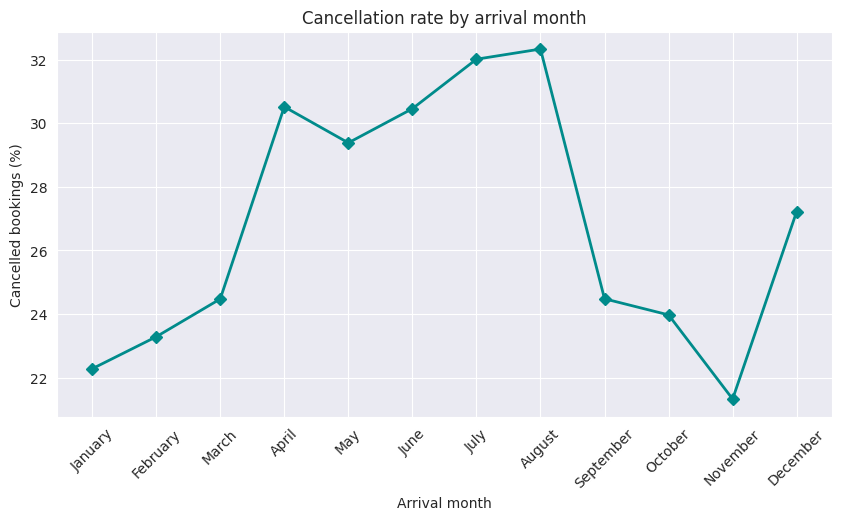

INSIGHT: Cancellations peak in August (32.3%) and are lowest in November (21.3%), so the arrival month (season) is a useful feature for the model.


In [26]:
monthly_rate = df.groupby('arrival_date_month', observed=True)['is_canceled'].mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(monthly_rate.index.astype(str), monthly_rate.values, marker='D', color='darkcyan', linewidth=2)
plt.title('Cancellation rate by arrival month')
plt.xlabel('Arrival month')
plt.ylabel('Cancelled bookings (%)')
plt.xticks(rotation=45)
plt.show()

print(f'INSIGHT: Cancellations peak in {monthly_rate.idxmax()} ({monthly_rate.max():.1f}%) and are lowest in '
      f'{monthly_rate.idxmin()} ({monthly_rate.min():.1f}%), so the arrival month (season) is a useful feature for the model.')

# 3. Feature Engineering (20%)

Plan: new features -> binning -> encoding -> feature selection -> test whether scaling is needed.

### 3.1 Create new features and bin skewed ones

Binning replaces a continuous value by a few ranges. This reduces the pull of extreme values and makes patterns simpler to learn.

In [27]:
data = df.copy()

# --- new features (merge columns that describe the same thing) ---
data['total_nights'] = data['stays_in_weekend_nights'] + data['stays_in_week_nights']
data['total_guests'] = data[['adults', 'children', 'babies']].sum(axis=1)
data['has_kids'] = (data[['children', 'babies']].sum(axis=1) > 0).astype(int)
data['was_on_waiting_list'] = (data['days_in_waiting_list'] > 0).astype(int)

# season derived from the month number (1 = January ... 12 = December)
month_num = data['arrival_date_month'].cat.codes + 1
data['season'] = np.select([month_num.isin([12, 1, 2]), month_num.isin([3, 4, 5]), month_num.isin([6, 7, 8])],
                           ['Winter', 'Spring', 'Summer'], default='Autumn')

# country has 170+ values -> keep the 8 most common ones and group the rest as 'Other'
top_countries = data['country'].value_counts().head(8).index
data['country_group'] = data['country'].astype(str).where(data['country'].isin(top_countries), 'Other')

# --- binning (ordered groups 0, 1, 2, ...) ---
# lead_time (days between booking and arrival): 0 = up to 2 weeks ... 4 = more than 300 days ahead
data['lead_time_group'] = pd.cut(data['lead_time'], bins=[-1, 14, 60, 150, 300, 1000],
                                 labels=[0, 1, 2, 3, 4]).astype(int)

# total_nights: 0 = 1 night, 1 = 2-3 nights, 2 = 4-7 nights, 3 = more than 7 nights
data['stay_group'] = pd.cut(data['total_nights'], bins=[0, 1, 3, 7, 100],
                            labels=[0, 1, 2, 3]).astype(int)

print(data[['lead_time', 'lead_time_group', 'total_nights', 'stay_group']].head())
print()
print(data['lead_time_group'].value_counts().sort_index())
print(data['stay_group'].value_counts().sort_index())

   lead_time  lead_time_group  total_nights  stay_group
2          7                0             1           0
3         13                0             1           0
4         14                0             2           1
5          0                0             2           1
6          9                0             2           1

lead_time_group
0    23959
1    23333
2    22200
3    14641
4     2254
Name: count, dtype: int64
stay_group
0    17138
1    33468
2    30968
3     4813
Name: count, dtype: int64


**Reasoning**
- `total_nights`, `total_guests` and `has_kids` merge several columns into one clearer value, so the feature set is smaller and less repetitive.
- `was_on_waiting_list` stands in for `days_in_waiting_list`, which is 0 for almost all bookings.
- `season` condenses the month into 4 groups; `country_group` reduces 170+ countries to 9 groups, which keeps the one-hot encoding small.
- `lead_time` and `total_nights` are skewed with extreme values, so they are **binned** into ordered groups. `adr` stays numeric since the exact price carries a lot of information.

In [28]:
# Remove the original columns that have been replaced by the new / binned features
replaced_cols = ['stays_in_weekend_nights', 'stays_in_week_nights', 'total_nights',
                 'adults', 'children', 'babies', 'days_in_waiting_list',
                 'lead_time', 'arrival_date_month', 'country']
data = data.drop(columns=replaced_cols)
print(data.columns.tolist())

['hotel', 'is_canceled', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'has_kids', 'was_on_waiting_list', 'season', 'country_group', 'lead_time_group', 'stay_group']


### 3.2 Encoding

Models need numbers, so the unordered (nominal) text columns are **one-hot encoded** with `get_dummies`; `drop_first=True` leaves out one column per feature so no information is duplicated. The binned features are already ordered numbers (ordinal encoding) and the 0/1 flags can be used as they are.

In [29]:
nominal_cols = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type',
                'deposit_type', 'customer_type', 'season', 'country_group']

data[nominal_cols] = data[nominal_cols].astype(str)
data = pd.get_dummies(data, columns=nominal_cols, drop_first=True, dtype=int)

print('Shape after encoding:', data.shape)
data.head()

Shape after encoding: (86387, 50)


,is_canceled,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,adr,required_car_parking_spaces,total_of_special_requests,total_guests,has_kids,...,season_Summer,season_Winter,country_group_DEU,country_group_ESP,country_group_FRA,country_group_GBR,country_group_IRL,country_group_ITA,country_group_Other,country_group_PRT
2,0,0,0,0,0,75.0,0,0,1,0,...,1,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,75.0,0,0,1,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,98.0,0,1,2,0,...,1,0,0,0,0,1,0,0,0,0
5,0,0,0,0,0,107.0,0,0,2,0,...,1,0,0,0,0,0,0,0,0,1
6,0,0,0,0,0,103.0,0,1,2,0,...,1,0,0,0,0,0,0,0,0,1


### 3.3 Feature selection

I drop features that add little or repeat what other features say. The target is not used here, so nothing from the test data can leak in:
1. **Near-constant features** hardly ever change value, so they cannot help.
2. **Strongly correlated features** (correlation above 0.85) carry the same information twice.

In [30]:
# 1) near-constant features
feature_cols = [c for c in data.columns if c != 'is_canceled']
variances = data[feature_cols].var()
low_var = variances[variances < 0.005].index.tolist()
print('Near-constant features removed:', low_var)
data = data.drop(columns=low_var)

# 2) highly correlated pairs (absolute correlation > 0.85)
feature_cols = [c for c in data.columns if c != 'is_canceled']
corr_matrix = data[feature_cols].corr().abs()
corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if corr_matrix.iloc[i, j] > 0.85:
            corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], round(corr_matrix.iloc[i, j], 2)))
print('Highly correlated pairs:', corr_pairs)

Near-constant features removed: ['meal_FB', 'distribution_channel_GDS', 'reserved_room_type_L', 'deposit_type_Refundable']
Highly correlated pairs: [('market_segment_Direct', 'distribution_channel_Direct', np.float64(0.92)), ('customer_type_Transient', 'customer_type_Transient-Party', np.float64(0.85))]


In [31]:
# Drop the second feature of every highly correlated pair
redundant = sorted({pair[1] for pair in corr_pairs})
print('Dropping:', redundant)
data = data.drop(columns=redundant)
print('Final number of features:', data.shape[1] - 1)

Dropping: ['customer_type_Transient-Party', 'distribution_channel_Direct']
Final number of features: 43


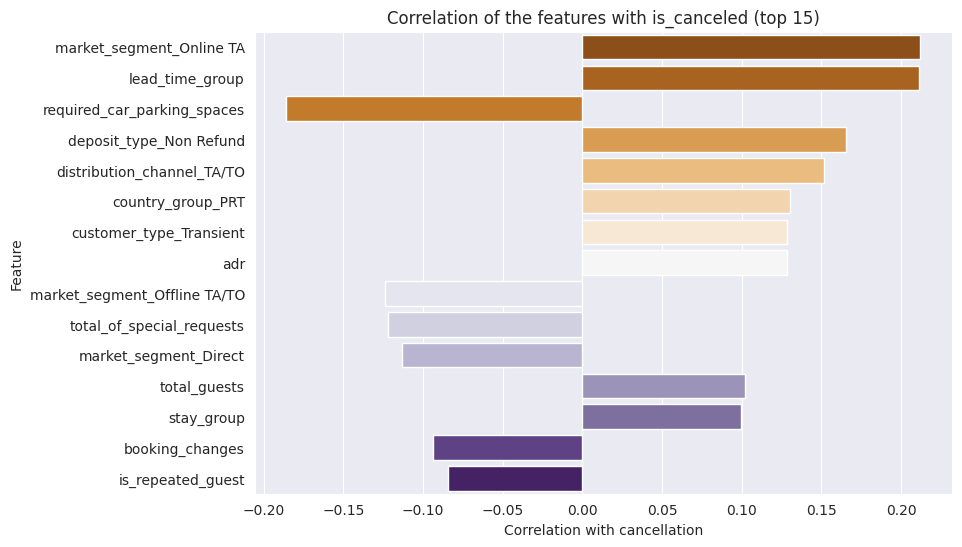

In [32]:
# Correlation of each feature with cancellation (top 15 by absolute value)
target_corr = data.corr()['is_canceled'].drop('is_canceled')
top_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_corr.values, y=top_corr.index, hue=top_corr.index, palette='PuOr', legend=False)
plt.title('Correlation of the features with is_canceled (top 15)')
plt.xlabel('Correlation with cancellation')
plt.ylabel('Feature')
plt.show()

### 3.4 Is scaling necessary?

Scaling (e.g. `StandardScaler`) is important for distance- or gradient-based models such as KNN, SVM, logistic regression and neural networks. **Decision trees and random forests split on thresholds, so a feature's scale makes no difference to them.** I verify this by training the same tree with and without scaling.

In [33]:
X_all = data.drop(columns=['is_canceled'])
y_all = data['is_canceled']

# temporary split just for this experiment (the scaler is fitted on the training part only)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_all, y_all, test_size=0.3,
                                                        random_state=RANDOM_STATE, stratify=y_all)

# without scaling
tree_raw = DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE).fit(Xa_train, ya_train)
acc_raw = accuracy_score(ya_test, tree_raw.predict(Xa_test))

# with scaling
scaler = StandardScaler()
Xa_train_sc = scaler.fit_transform(Xa_train)
Xa_test_sc = scaler.transform(Xa_test)
tree_sc = DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE).fit(Xa_train_sc, ya_train)
acc_sc = accuracy_score(ya_test, tree_sc.predict(Xa_test_sc))

print(f'Accuracy without scaling: {acc_raw:.4f}')
print(f'Accuracy with scaling   : {acc_sc:.4f}')

Accuracy without scaling: 0.8072
Accuracy with scaling   : 0.8072


**Conclusion:** The two accuracies are (nearly) equal, so **scaling is not required** for tree-based models. I carry on with the unscaled data, which keeps the feature values readable.

# 4. Classifier Training (20%)

The main model is a **Decision Tree** (easy to explain and it provides feature importance). I compare it with a **Random Forest** and with a naive baseline that always predicts the majority class.

## 4.1. Data Splitting (5%)

In [34]:
# Input features (X) and target (y)
X = data.drop(columns=['is_canceled'])
y = data['is_canceled']

# 70% training / 30% testing, stratified so both parts keep the same share of cancelled bookings
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=RANDOM_STATE, stratify=y)

print('Training set:', X_train.shape, '| Test set:', X_test.shape)
print()
print('Share of cancelled bookings:')
print(f'  all data: {y.mean():.3f}')
print(f'  train   : {y_train.mean():.3f}')
print(f'  test    : {y_test.mean():.3f}')

Training set: (60470, 43) | Test set: (25917, 43)

Share of cancelled bookings:
  all data: 0.276
  train   : 0.277
  test    : 0.276


## 4.2. Model Training (10%)

In [35]:
# Baseline: always predict the most common class (the accuracy any real model has to beat)
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

# Model 1: decision tree with default settings (tends to over-fit)
tree_default = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_default.fit(X_train, y_train)
print('Default tree  -> train accuracy:', round(tree_default.score(X_train, y_train), 4),
      '| test accuracy:', round(tree_default.score(X_test, y_test), 4))

Default tree  -> train accuracy: 0.9793 | test accuracy: 0.7725


In [36]:
# Model 2: decision tree tuned with 5-fold cross-validation on the TRAINING data only
param_grid = {'max_depth': [4, 6, 8, 12, 18, 25],
              'min_samples_leaf': [1, 10, 25, 40, 100],
              'criterion': ['gini', 'entropy']}

grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                    cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best cross-validation accuracy:', round(grid.best_score_, 4))

tree = grid.best_estimator_    # the final decision tree model

Best parameters: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 10}
Best cross-validation accuracy: 0.8106


In [37]:
# Model 3: random forest (for comparison)
forest = RandomForestClassifier(n_estimators=200, max_depth=18, min_samples_leaf=4,
                                random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(X_train, y_train)
print('Random forest trained.')

Random forest trained.


**Reasoning:** One decision tree is easy to read and shows which features drive its choices. An unrestricted tree keeps splitting until it has memorised the training data (very high train accuracy, lower test accuracy), so I restrict its size (`max_depth`, `min_samples_leaf`) and choose the settings by cross-validation on the training set alone. The test set plays no part in tuning.

## 4.3. Model Evaluation (5%)

In [38]:
# Accuracy and other metrics of all models, measured on the TEST set
models = {'Baseline (majority class)': baseline,
          'Decision Tree (default)': tree_default,
          'Decision Tree (tuned)': tree,
          'Random Forest': forest}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({'Model': name,
                 'Train accuracy': accuracy_score(y_train, model.predict(X_train)),
                 'Test accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred),
                 'F1-score': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, prob)})

results_df = pd.DataFrame(rows).set_index('Model').round(4)
results_df

,Train accuracy,Test accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
Baseline (majority class),0.7235,0.7235,0.0000,0.0000,0.0000,0.5000
Decision Tree (default),0.9793,0.7725,0.5873,0.5966,0.5919,0.7309
Decision Tree (tuned),0.8232,0.8124,0.6999,0.5625,0.6238,0.8619
Random Forest,0.8352,0.8233,0.7464,0.5466,0.6311,0.8810


               precision    recall  f1-score   support

Not cancelled       0.84      0.91      0.88     18751
    Cancelled       0.70      0.56      0.62      7166

     accuracy                           0.81     25917
    macro avg       0.77      0.74      0.75     25917
 weighted avg       0.80      0.81      0.81     25917



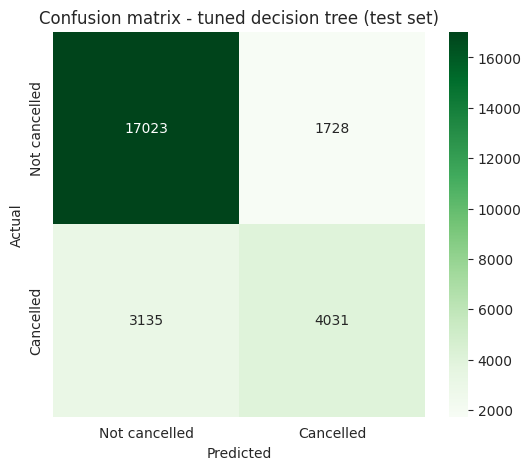

Test accuracy of the decision tree: 81.24%
Target of 70% reached!


In [39]:
# Detailed evaluation of the final (tuned) decision tree
y_pred = tree.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Not cancelled', 'Cancelled']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not cancelled', 'Cancelled'], yticklabels=['Not cancelled', 'Cancelled'])
plt.title('Confusion matrix - tuned decision tree (test set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

test_acc = accuracy_score(y_test, y_pred)
print(f'Test accuracy of the decision tree: {test_acc * 100:.2f}%')
print('Target of 70% reached!' if test_acc > 0.70 else 'Target of 70% NOT reached.')

**Evaluation:** When the classes are unbalanced, accuracy can mislead: only about a quarter to a third of the bookings are cancelled, so a model that *always* says "not cancelled" already reaches a high accuracy (the baseline row, which has zero recall). For that reason I also report precision, recall, F1-score and ROC-AUC. The tuned tree should beat the baseline clearly on these measures, with only a small gap between train and test accuracy (no strong over-fitting). The default tree typically over-fits, with near-perfect train accuracy and a noticeably lower test accuracy, which shows why tuning is worthwhile. In the confusion matrix, *false negatives* (a cancelled booking predicted as kept) are the expensive mistake for a hotel, as the room is then not resold. (Compare these remarks with the numbers in your own results.)

# 5. Feature Importance (10%)

Look at how important each feature is inside the decision tree, and comment on how far the results can be trusted.

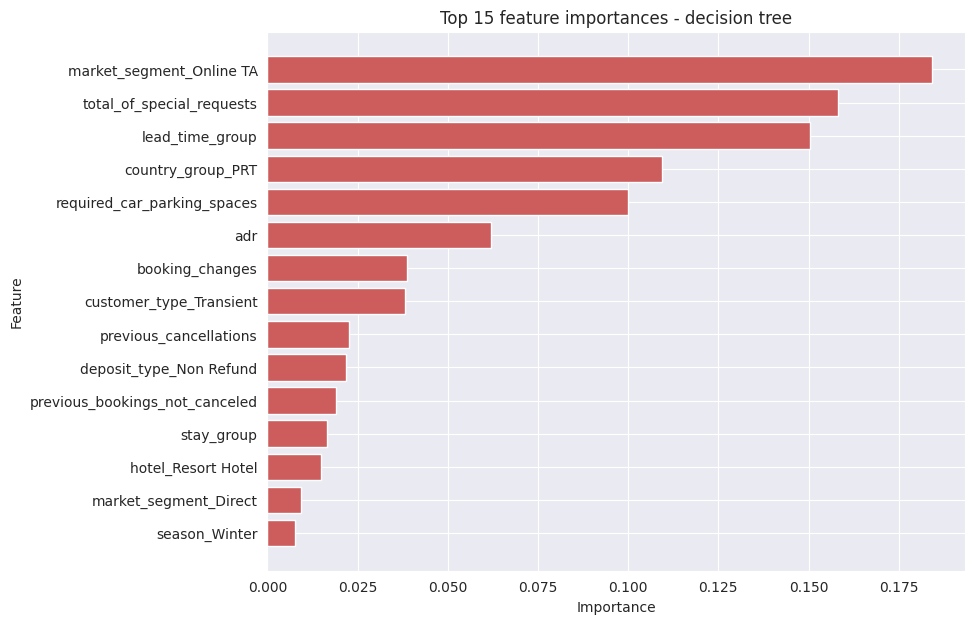

market_segment_Online TA       0.1841
total_of_special_requests      0.1581
lead_time_group                0.1505
country_group_PRT              0.1094
required_car_parking_spaces    0.0999
adr                            0.0621
booking_changes                0.0388
customer_type_Transient        0.0382
previous_cancellations         0.0226
deposit_type_Non Refund        0.0217
dtype: float64


In [40]:
# Importance according to the decision tree (impurity-based)
imp_tree = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)

top15 = imp_tree.head(15).sort_values()
plt.figure(figsize=(9, 7))
plt.barh(top15.index, top15.values, color='indianred')
plt.title('Top 15 feature importances - decision tree')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

print(imp_tree.head(10).round(4))

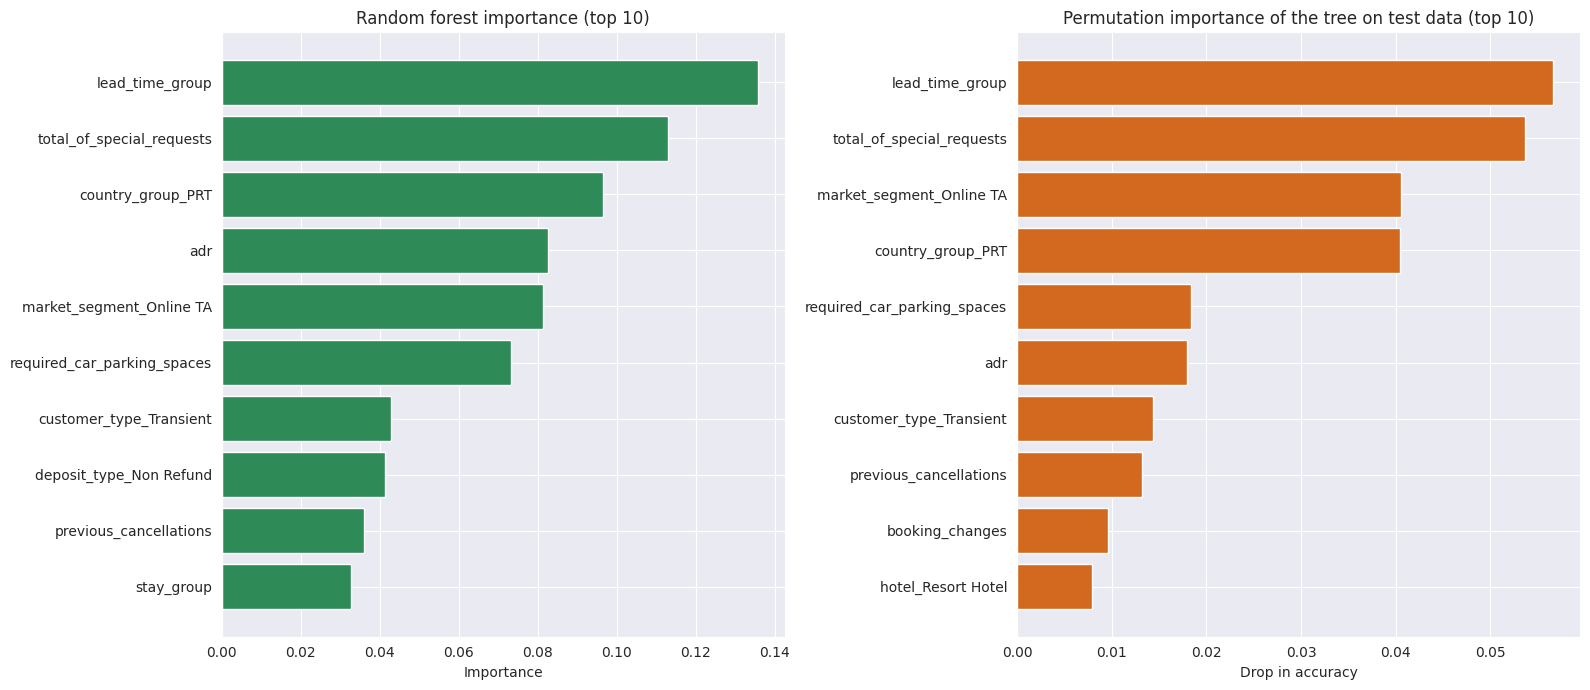

In the top 10 of all three methods: ['adr', 'country_group_PRT', 'customer_type_Transient', 'lead_time_group', 'market_segment_Online TA', 'previous_cancellations', 'required_car_parking_spaces', 'total_of_special_requests']
Tree and permutation agree on 9 of 10 features
Tree and forest agree on 9 of 10 features


In [41]:
# Check 1: random forest importance (an average over many trees, so more stable)
imp_forest = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)

# Check 2: permutation importance on the TEST set (how much accuracy is lost when a feature is shuffled?)
perm = permutation_importance(tree, X_test, y_test, n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
top_f = imp_forest.head(10).sort_values()
axes[0].barh(top_f.index, top_f.values, color='seagreen')
axes[0].set_title('Random forest importance (top 10)')
axes[0].set_xlabel('Importance')
top_p = imp_perm.head(10).sort_values()
axes[1].barh(top_p.index, top_p.values, color='chocolate')
axes[1].set_title('Permutation importance of the tree on test data (top 10)')
axes[1].set_xlabel('Drop in accuracy')
plt.tight_layout()
plt.show()

# How much do the three rankings agree?
top_tree = set(imp_tree.head(10).index)
top_forest = set(imp_forest.head(10).index)
top_perm = set(imp_perm.head(10).index)
print('In the top 10 of all three methods:', sorted(top_tree & top_forest & top_perm))
print('Tree and permutation agree on', len(top_tree & top_perm), 'of 10 features')
print('Tree and forest agree on', len(top_tree & top_forest), 'of 10 features')

### Commentary on the reliability of the results

The charts above usually put the following features near the top: whether the guest is from Portugal (`country_group_PRT`), the number of special requests, the lead time group, the Online Travel Agent segment, required parking spaces, the deposit type, `adr` and earlier cancellations. This is sensible from a business view: guests who request extras or a parking space are more likely to turn up, while bookings made long in advance through online agencies are easy to cancel.

The importance results are a reasonable guide for hotel management, for example, watch long-lead-time, no-deposit bookings and guests who cancelled before.

In [42]:
# Extra check: does the model still work with only the 15 most important features?
top_features = imp_tree.head(15).index.tolist()

tree_small = DecisionTreeClassifier(**grid.best_params_, random_state=RANDOM_STATE)
tree_small.fit(X_train[top_features], y_train)
acc_small = accuracy_score(y_test, tree_small.predict(X_test[top_features]))

print(f'Accuracy with all {X.shape[1]} features : {test_acc:.4f}')
print(f'Accuracy with top 15 features : {acc_small:.4f}')

Accuracy with all 43 features : 0.8124
Accuracy with top 15 features : 0.8146


As the accuracy with only the top 15 features is close to the accuracy with all features, the model is simpler and cheaper to run without losing quality, which also supports the importance ranking.